# Inspecting the baseline CNN

Run this from the same folder as `train_baseline.py`. It needs `data/manifest_split.csv`,
`best_model.pt` and `training_log.csv`, all created by running `train_baseline.py`.
Run the cells top to bottom; each section says what to look for.

**One rule while developing:** inspect the **validation** set (`SPLITS = ["val"]` below), and
make decisions about the model from that. The test set should only be looked at once the
model is settled, because every time you change the model after seeing test results, the test
set stops being an honest check.

In [2]:
%matplotlib inline
import os
os.chdir(r"F:\erdos_datascience\autism\fall-2026-autism\fall-2026-autism")
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix

import train_baseline as tb      # reuse the model, dataset and helpers from the training script

SPLITS = ["val"]                 # add "test" only for the final look

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
manifest = pd.read_csv(tb.MANIFEST_SPLIT)
print("device:", device)
print(manifest.groupby("split").agg(scans=("scan_id", "size"), subjects=("sub_id", "nunique")))

device: cuda
       scans  subjects
split                 
test      20        20
train     89        89
val       20        20


## 1. Did training behave?

**Left:** training loss should fall. If it stays flat, something is wrong with the setup.
**Right:** validation AUC (0.5 = chance, shown dashed). If train loss keeps falling while
validation AUC stalls or drops, the model is memorizing the training scans (overfitting).

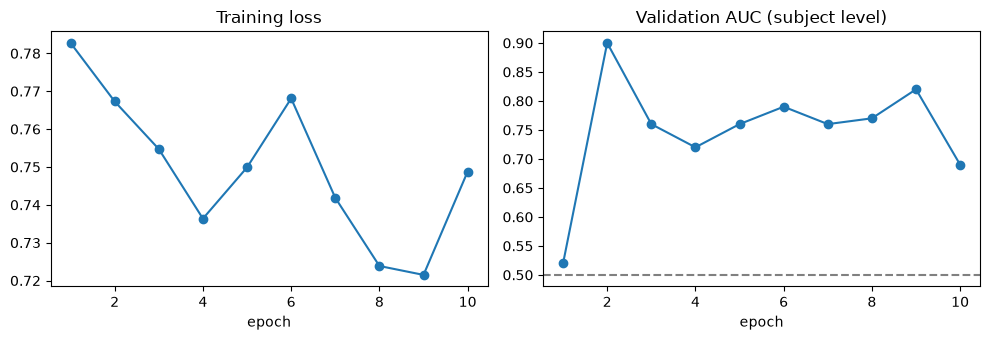

In [3]:
try:
    log = pd.read_csv("training_log.csv")
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
    ax[0].plot(log["epoch"], log["train_loss"], marker="o")
    ax[0].set_title("Training loss"); ax[0].set_xlabel("epoch")
    ax[1].plot(log["epoch"], log["val_auc"], marker="o")
    ax[1].axhline(0.5, ls="--", color="gray")
    ax[1].set_title("Validation AUC (subject level)"); ax[1].set_xlabel("epoch")
    plt.tight_layout(); plt.show()
except FileNotFoundError:
    print("training_log.csv not found: re-run train_baseline.py (the updated version writes it).")

## 2. What do the scans look like at each site?

One middle axial slice from one subject per site. Look for differences that have nothing to do
with biology: brightness and contrast, how much empty space surrounds the head (field of view),
blurriness, and how much skull/scalp is visible. Whatever differs here is something the CNN
could use to recognize the site.

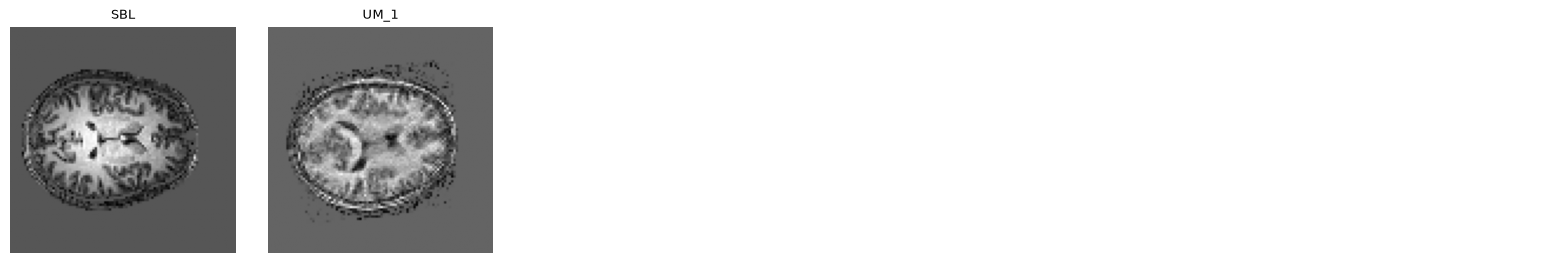

In [4]:
def load_vol(path):
    return torch.load(path)["vol"].float()          # (1, D, H, W)

sites = sorted(manifest["site"].dropna().unique())
cols = 6
rows = int(np.ceil(len(sites) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(2.6 * cols, 2.6 * rows))
axes = np.atleast_1d(axes).ravel()
for ax in axes:
    ax.axis("off")
for ax, site in zip(axes, sites):
    row = manifest[manifest["site"] == site].iloc[0]
    vol = load_vol(row["pt_path"])
    ax.imshow(vol[0, vol.shape[1] // 2], cmap="gray")
    ax.set_title(site, fontsize=9)
plt.tight_layout(); plt.show()

## 3. Data sanity checks and site fingerprints

For every scan we compute a few simple summaries: the fraction of non-zero voxels (how much of
the box the head fills), the maximum and median intensity after normalization, and
"sharpness" (average difference between neighbouring voxels, lower = blurrier).

**First check:** the count of scans with `inf`/NaN should be 0. **Then:** if these summaries
form separate clusters by site in the boxplots, preprocessing leaves site fingerprints. That
isn't automatically a problem, but it shows what a CNN could pick up on.

scans with inf/NaN: 0 of 129


,nonzero_frac,median_nz,max,sharpness
site,,,,
SBL,3.455,-0.179,2.757,1.389
UM_1,3.619,-0.155,4.007,1.281


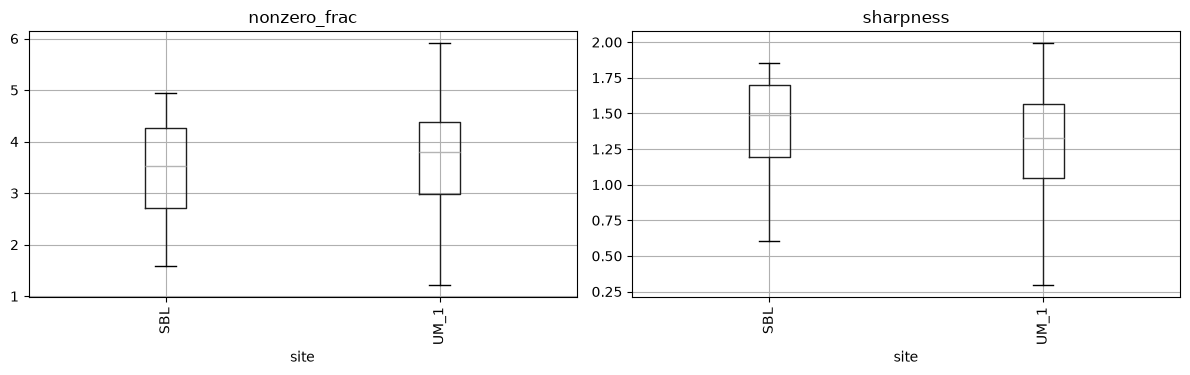

In [5]:
rows = []
for _, r in manifest.iterrows():
    v = torch.load(r["pt_path"])["vol"].float()
    nz = v != 0
    rows.append(dict(
        scan_id=r["scan_id"], sub_id=r["sub_id"], site=r["site"], label=r["label"], split=r["split"],
        finite=bool(torch.isfinite(v).all()),
        nonzero_frac=nz.float().mean().item(),
        median_nz=v[nz].median().item() if nz.any() else float("nan"),
        max=v.max().item(),
        sharpness=(v[:, 1:] - v[:, :-1]).abs().mean().item()))
feat = pd.DataFrame(rows)

print("scans with inf/NaN:", int((~feat["finite"]).sum()), "of", len(feat))
display(feat.groupby("site")[["nonzero_frac", "median_nz", "max", "sharpness"]].mean().round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
feat.boxplot(column="nonzero_frac", by="site", rot=90, ax=ax[0])
feat.boxplot(column="sharpness", by="site", rot=90, ax=ax[1])
plt.suptitle(""); plt.tight_layout(); plt.show()

## 4. Load the trained model and predict

The model gives one probability per scan; here they are averaged to one probability per
subject (that's what `per_subject` does). Everything below uses these predictions for the
splits in `SPLITS`.

In [6]:
model = tb.Baseline3DCNN().to(device)
model.load_state_dict(torch.load(tb.CHECKPOINT, map_location=device))
model.eval()

inspect_df = manifest[manifest["split"].isin(SPLITS)]
pred = tb.per_subject(tb.predict(model, inspect_df, batch_size=4, device=device))
print(f"{len(pred)} subjects in {SPLITS}; autism fraction {pred['label'].mean():.2f}")
pred.head()

20 subjects in ['val']; autism fraction 0.50


,sub_id,label,site,prob
0,50272,1,UM_1,0.527644
1,50282,1,UM_1,0.519406
2,50283,1,UM_1,0.535496
3,50286,1,UM_1,0.537617
4,50288,1,UM_1,0.527769


## 5. Does the model separate the two groups?

Histogram of predicted P(autism), split by the true diagnosis.

- Two clearly different humps: the model separates the groups well (unusual for this dataset).
- Heavily overlapping humps: weak separation, which is the typical honest result.
- Everything bunched near 0.5: the model hasn't found much signal.
- Everything pushed to 0 or 1: overconfident, usually a sign of overfitting.

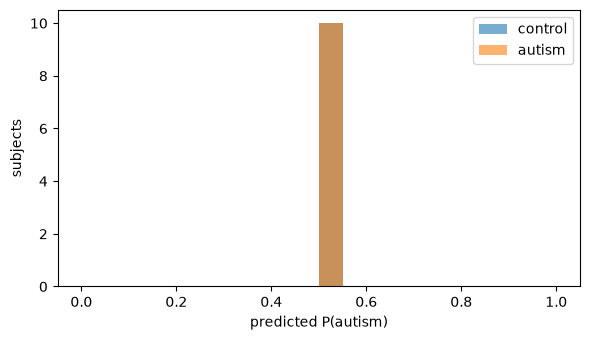

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for lab, name in [(0, "control"), (1, "autism")]:
    ax.hist(pred.loc[pred["label"] == lab, "prob"], bins=np.linspace(0, 1, 21), alpha=0.6, label=name)
ax.set_xlabel("predicted P(autism)"); ax.set_ylabel("subjects"); ax.legend()
plt.tight_layout(); plt.show()

## 6. ROC curve and confusion matrix

The ROC curve shows the trade-off between catching autistic subjects and falsely flagging
controls as you move the cutoff; the diagonal is chance. The confusion matrix uses the
default 0.5 cutoff. Compare the accuracy with always guessing the majority class.

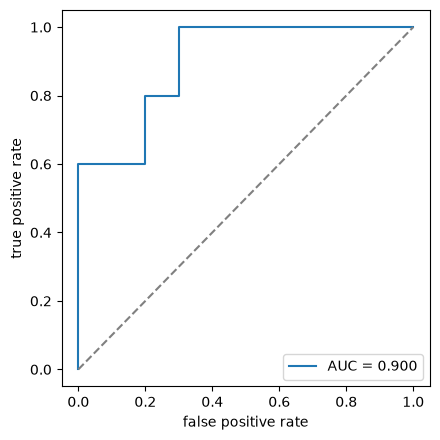

,pred control,pred autism
true control,0,10
true autism,0,10


accuracy 0.500 vs majority-class accuracy 0.500


In [8]:
fpr, tpr, _ = roc_curve(pred["label"], pred["prob"])
auc = roc_auc_score(pred["label"], pred["prob"])
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
ax.plot([0, 1], [0, 1], ls="--", color="gray")
ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate"); ax.legend()
plt.tight_layout(); plt.show()

cm = confusion_matrix(pred["label"], (pred["prob"] >= 0.5).astype(int))
display(pd.DataFrame(cm, index=["true control", "true autism"], columns=["pred control", "pred autism"]))
acc = (cm[0, 0] + cm[1, 1]) / cm.sum()
majority = max(pred["label"].mean(), 1 - pred["label"].mean())
print(f"accuracy {acc:.3f} vs majority-class accuracy {majority:.3f}")

## 7. Is the model just recognizing the site?

If different sites have different autism ratios, a model can score well by identifying the
scanner. The cleanest check is to compare:

- **overall AUC:** ranking all subjects together, against
- **within-site AUC:** ranking subjects only against others from the same site (averaged over
  sites with at least 10 subjects of this split).

If overall AUC is clearly higher than within-site AUC, part of the performance comes from
telling sites apart. Small sites give very noisy numbers, so don't read much into any single row.

,site,n,autism_frac,mean_prob,auc
1,UM_1,16,0.5,0.522,0.969
0,SBL,4,0.5,0.527,0.500


overall AUC: 0.900
within-site AUC (sites with n>=10, weighted): 0.969  (1 sites)


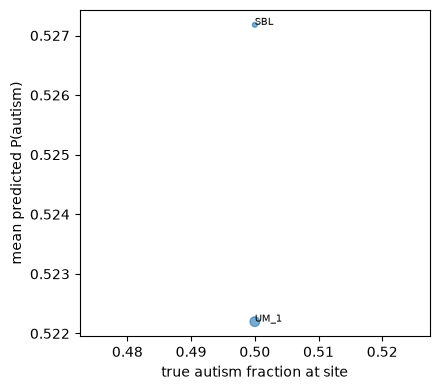

In [9]:
overall_auc = tb.safe_auc(pred["label"], pred["prob"])
rows = []
for site, g in pred.groupby("site"):
    rows.append(dict(site=site, n=len(g), autism_frac=g["label"].mean(),
                     mean_prob=g["prob"].mean(), auc=tb.safe_auc(g["label"], g["prob"])))
site_tab = pd.DataFrame(rows).sort_values("n", ascending=False)
display(site_tab.round(3))

big = site_tab[(site_tab["n"] >= 10) & site_tab["auc"].notna()]
within = np.average(big["auc"], weights=big["n"]) if len(big) else float("nan")
print(f"overall AUC: {overall_auc:.3f}")
print(f"within-site AUC (sites with n>=10, weighted): {within:.3f}  ({len(big)} sites)")

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.scatter(site_tab["autism_frac"], site_tab["mean_prob"], s=site_tab["n"] * 3, alpha=0.6)
for _, r in site_tab.iterrows():
    ax.annotate(r["site"], (r["autism_frac"], r["mean_prob"]), fontsize=7)
ax.set_xlabel("true autism fraction at site"); ax.set_ylabel("mean predicted P(autism)")
plt.tight_layout(); plt.show()

## 8. Where is the model looking? (Grad-CAM)

Grad-CAM highlights the regions that pushed the model's output **toward "autism"** for a given
scan (bright = strong push). It's computed from the third convolutional block, so it is coarse
(12x12x12 upsampled to the full volume). Regions pushing toward "control" are not shown.

Shown: the two most confidently-autism and two most confidently-control subjects.

**Treat this with caution.** Heatmaps are suggestive, not proof of anything anatomical. They are
most useful for spotting problems: highlights on the skull, the image edges, or the background
suggest the model is using artifacts rather than brain. Axis labels assume the scans were
reoriented to a standard orientation by the preprocessing script.

c:\Users\doyby\.conda\envs\pytorch_env\Lib\site-packages\torch\autograd\graph.py:1072: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at C:\Users\task_178896504925232\croot\libtorch_1788965230773\work\aten\src\ATen\cuda\CublasHandlePool.cpp:410.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


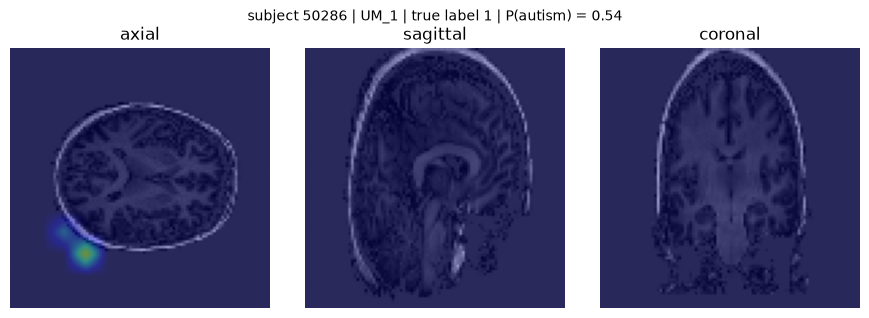

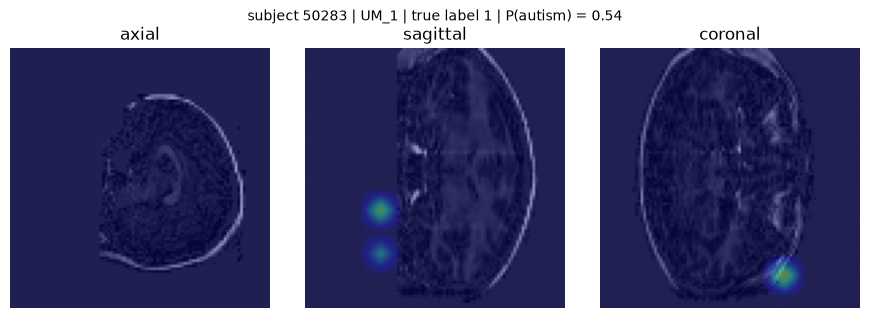

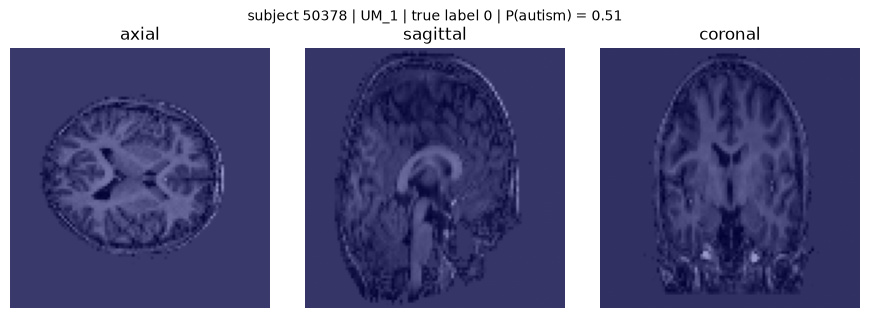

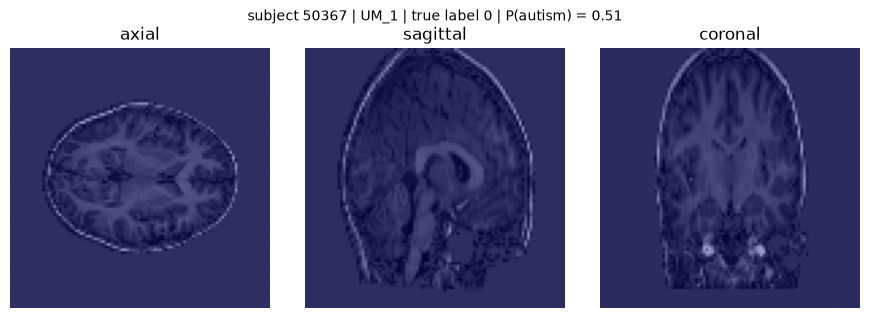

In [10]:
scan_of = manifest.drop_duplicates("sub_id").set_index("sub_id")["pt_path"]


def grad_cam(model, vol):
    model.eval()
    x = vol[None].to(device)                                  # add a batch dimension
    a = model.features[:3](x)                                 # activations after block 3: (1, 32, 12, 12, 12)
    a.retain_grad()
    logit = model.head(model.pool(model.features[3](a))).squeeze(1)
    model.zero_grad()
    logit.backward()
    w = a.grad.mean(dim=(2, 3, 4), keepdim=True)              # importance of each feature map
    cam = torch.relu((w * a).sum(dim=1, keepdim=True))        # keep only evidence for "autism"
    cam = torch.nn.functional.interpolate(cam, size=vol.shape[1:], mode="trilinear", align_corners=False)[0, 0]
    cam = cam / (cam.max() + 1e-8)
    return cam.detach().cpu().numpy(), torch.sigmoid(logit).item()


def show_cam(vol, cam, title):
    v = vol[0].numpy()
    k = [s // 2 for s in v.shape]
    views = [(v[k[0]], cam[k[0]], "axial"),
             (v[:, k[1], :], cam[:, k[1], :], "sagittal"),
             (v[:, :, k[2]], cam[:, :, k[2]], "coronal")]
    fig, axes = plt.subplots(1, 3, figsize=(9, 3.2))
    for ax, (im, c, name) in zip(axes, views):
        ax.imshow(im, cmap="gray", origin="lower")
        ax.imshow(c, cmap="jet", alpha=0.4, origin="lower", vmin=0, vmax=1)
        ax.set_title(name); ax.axis("off")
    fig.suptitle(title, fontsize=10)
    plt.tight_layout(); plt.show()


picks = pd.concat([pred[pred["label"] == 1].nlargest(2, "prob"),
                   pred[pred["label"] == 0].nsmallest(2, "prob")])
for _, r in picks.iterrows():
    vol = load_vol(scan_of[r["sub_id"]])
    cam, p = grad_cam(model, vol)
    show_cam(vol, cam, f"subject {r['sub_id']} | {r['site']} | true label {int(r['label'])} | P(autism) = {p:.2f}")

## 9. Average Grad-CAM, and how much of it lands in the background

Averages the maps over up to 40 subjects per group, which is more reliable than single examples.
Also reports the share of Grad-CAM weight that falls on background voxels (value exactly 0 after
preprocessing, i.e. outside the foreground mask) next to the share of the volume that is
background. If the model leans on the background much more than its share of the volume, it is
probably using scanner or preprocessing artifacts.

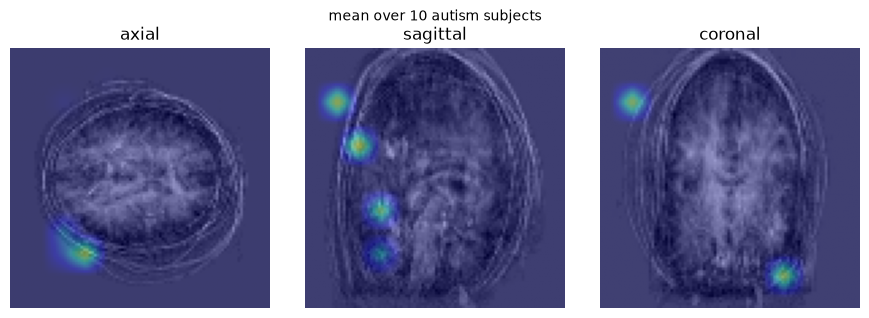

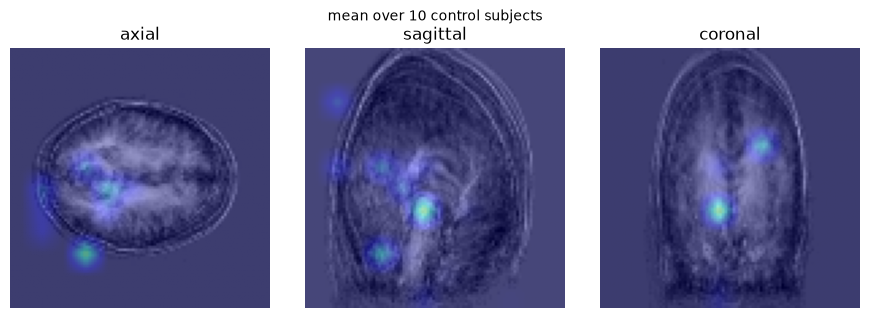

share of Grad-CAM weight on background voxels: 0.416
share of the volume that is background:        0.746


In [15]:
sum_cam, sum_vol, count, bg_rows = {}, {}, {0: 0, 1: 0}, []
sample = pd.concat([pred[pred["label"] == lab].sample(min(20, int((pred["label"] == lab).sum())), random_state=0)
                    for lab in (0, 1)])
for _, r in sample.iterrows():
    vol = load_vol(scan_of[r["sub_id"]])
    cam, _ = grad_cam(model, vol)
    lab = int(r["label"])
    sum_cam[lab] = cam if lab not in sum_cam else sum_cam[lab] + cam
    sum_vol[lab] = vol if lab not in sum_vol else sum_vol[lab] + vol
    count[lab] += 1
    bg = vol[0].numpy() == 0
    bg_rows.append(dict(cam_share_in_background=cam[bg].sum() / (cam.sum() + 1e-8), background_share_of_volume=bg.mean()))

for lab, name in [(1, "autism"), (0, "control")]:
    if lab in sum_cam:
        m = sum_cam[lab] / count[lab]
        show_cam(sum_vol[lab] / count[lab], m / (m.max() + 1e-8), f"mean over {count[lab]} {name} subjects")

bg_df = pd.DataFrame(bg_rows)
print("share of Grad-CAM weight on background voxels:", round(bg_df["cam_share_in_background"].mean(), 3))
print("share of the volume that is background:       ", round(bg_df["background_share_of_volume"].mean(), 3))

## 10. Which subjects does the model get most wrong?

The most confidently wrong subjects, with their age and sex. Look for patterns: one site
dominating the list, a particular age range, or scans that look odd (check them with the
slice viewer from section 2).

In [12]:
demo = manifest.drop_duplicates("sub_id")[["sub_id", "age", "sex"]]
errs = (pred.assign(error=(pred["prob"] - pred["label"]).abs())
            .merge(demo, on="sub_id")
            .sort_values("error", ascending=False))
display(errs.head(10).round(3))
print("sites among the 20 worst errors:")
print(errs.head(20)["site"].value_counts().to_string())

,sub_id,label,site,prob,error,age,sex
17,51566,0,SBL,0.527,0.527,41.0,1
16,51558,0,SBL,0.527,0.527,27.0,1
8,50333,0,UM_1,0.521,0.521,10.2,1
9,50353,0,UM_1,0.519,0.519,13.1,2
10,50362,0,UM_1,0.519,0.519,11.2,1
13,50370,0,UM_1,0.518,0.518,12.8,1
11,50366,0,UM_1,0.515,0.515,8.2,1
14,50371,0,UM_1,0.515,0.515,12.2,1
12,50367,0,UM_1,0.514,0.514,10.8,1
15,50378,0,UM_1,0.513,0.513,11.6,1


sites among the 20 worst errors:
site
UM_1    16
SBL      4


## 11. What do demographics and site alone predict?

Logistic regression (cross-validated over all subjects, no images) using only age and sex, only
site, or all three. This shows how much of the diagnosis is predictable without looking at the
brain at all. **The CNN has to beat these numbers to be learning something from the images.**
These use all subjects, while the CNN number above uses only the split you chose, so treat the
comparison as approximate.

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

subj = manifest.drop_duplicates("sub_id").reset_index(drop=True).copy()
subj["age"] = subj["age"].fillna(subj["age"].median())
subj["sex"] = subj["sex"].fillna(subj["sex"].mode()[0])
site_onehot = pd.get_dummies(subj["site"]).astype(float)
demo_x = subj[["age", "sex"]].astype(float)


def cv_auc(X):
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    p = cross_val_predict(clf, X, subj["label"],
                          cv=StratifiedKFold(5, shuffle=True, random_state=0),
                          method="predict_proba")[:, 1]
    return roc_auc_score(subj["label"], p)


results = {"age + sex": cv_auc(demo_x),
           "site only": cv_auc(site_onehot),
           "age + sex + site": cv_auc(pd.concat([demo_x, site_onehot], axis=1))}
for name, value in results.items():
    print(f"{name:18s} AUC {value:.3f}")
print(f"CNN on {SPLITS}: AUC {overall_auc:.3f}")

age + sex          AUC 0.559
site only          AUC 0.425
age + sex + site   AUC 0.542
CNN on ['val']: AUC 0.900


## 12. Can the site be predicted from simple image summaries?

A random forest tries to predict the **site** from the four summaries in section 3, using no
diagnosis information and keeping each subject's scans together when cross-validating. If
accuracy is far above the chance level (always guessing the biggest site), the preprocessed
scans carry strong site fingerprints, and a CNN can use them too.

In [14]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold

feat_ok = feat.dropna(subset=["site", "median_nz"])
X_site = feat_ok[["nonzero_frac", "median_nz", "max", "sharpness"]].values
y_site = feat_ok["site"].astype(str).values
pred_site = cross_val_predict(RandomForestClassifier(n_estimators=200, random_state=0),
                              X_site, y_site, groups=feat_ok["sub_id"], cv=GroupKFold(5))
print(f"site prediction accuracy: {(pred_site == y_site).mean():.3f}")
print(f"chance (always the biggest site): {pd.Series(y_site).value_counts(normalize=True).max():.3f}")

site prediction accuracy: 0.992
chance (always the biggest site): 0.798


## How to use all this

- **Sections 1, 5 and 6** tell you whether the model learned anything.
- **Sections 7, 11 and 12** tell you whether what it learned is likely to be the site rather
  than the brain. If section 7 shows within-site AUC near 0.5, the performance is mostly site.
- **Sections 8, 9 and 10** are for spotting odd behavior, not for drawing biological conclusions.

Next experiments to compare against this baseline: MNI registration and skull-stripping, then
the demographic adjustments you planned, re-running this notebook each time.